In [2]:
import pandas as pd

df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [3]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

df = df.dropna(subset=["TotalCharges"]).copy()

df = df.drop(columns=["customerID"])

In [4]:
df.shape

(7032, 20)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7032 non-null   object 
 1   SeniorCitizen     7032 non-null   int64  
 2   Partner           7032 non-null   object 
 3   Dependents        7032 non-null   object 
 4   tenure            7032 non-null   int64  
 5   PhoneService      7032 non-null   object 
 6   MultipleLines     7032 non-null   object 
 7   InternetService   7032 non-null   object 
 8   OnlineSecurity    7032 non-null   object 
 9   OnlineBackup      7032 non-null   object 
 10  DeviceProtection  7032 non-null   object 
 11  TechSupport       7032 non-null   object 
 12  StreamingTV       7032 non-null   object 
 13  StreamingMovies   7032 non-null   object 
 14  Contract          7032 non-null   object 
 15  PaperlessBilling  7032 non-null   object 
 16  PaymentMethod     7032 non-null   object 
 17  

In [6]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

In [7]:
X.shape

(7032, 19)

In [8]:
y.head()

0     No
1     No
2    Yes
3     No
4    Yes
Name: Churn, dtype: object

In [9]:
y = y.map({
    "No": 0,
    "Yes": 1
})

In [10]:
y.value_counts()

Churn
0    5163
1    1869
Name: count, dtype: int64

In [11]:
categorical_cols = X.select_dtypes(
    include="object"
).columns.tolist()

categorical_cols

['gender',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod']

In [12]:
numerical_cols = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

numerical_cols

['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

In [13]:
X_encoded = pd.get_dummies(
    X,
    columns=categorical_cols,
    drop_first=True
)
X_encoded.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,False,True,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,True,False,False,True,False,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,True,False,False,True,False,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,True,False,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,False,False,False,True,False,False,...,False,False,False,False,False,False,True,False,True,False


In [14]:
X_encoded.shape

(7032, 30)

In [15]:
X_encoded.columns

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges',
       'gender_Male', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes',
       'MultipleLines_No phone service', 'MultipleLines_Yes',
       'InternetService_Fiber optic', 'InternetService_No',
       'OnlineSecurity_No internet service', 'OnlineSecurity_Yes',
       'OnlineBackup_No internet service', 'OnlineBackup_Yes',
       'DeviceProtection_No internet service', 'DeviceProtection_Yes',
       'TechSupport_No internet service', 'TechSupport_Yes',
       'StreamingTV_No internet service', 'StreamingTV_Yes',
       'StreamingMovies_No internet service', 'StreamingMovies_Yes',
       'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes',
       'PaymentMethod_Credit card (automatic)',
       'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check'],
      dtype='object')

In [16]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

y = y.map({
    "No": 0,
    "Yes": 1
})

categorical_cols = X.select_dtypes(
    include="object"
).columns.tolist()

X_encoded = pd.get_dummies(
    X,
    columns=categorical_cols,
    drop_first=True
)

In [17]:
X_encoded.shape

(7032, 30)

In [18]:
X_encoded.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,False,True,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,True,False,False,True,False,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,True,False,False,True,False,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,True,False,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,False,False,False,True,False,False,...,False,False,False,False,False,False,True,False,True,False


In [19]:
from sklearn.model_selection import train_test_split

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [21]:
X_train.shape

(5625, 30)

In [22]:
X_test.shape

(1407, 30)

In [23]:
y_train.value_counts(normalize=True)

Churn
0    0.734222
1    0.265778
Name: proportion, dtype: float64

In [24]:
y_test.value_counts(normalize=True)

Churn
0    0.734186
1    0.265814
Name: proportion, dtype: float64

Import Model

In [25]:
from sklearn.linear_model import LogisticRegression

Build Model

In [26]:
model = LogisticRegression(max_iter=1000)

Training Model

In [27]:
model.fit(X_train, y_train)

/Users/wuyutong/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/wuyutong/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/wuyutong/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/wuyutong/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/wuyutong/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features] = X.T @ grad_point

LogisticRegression(max_iter=1000)

In [28]:
y_pred = model.predict(X_test)

/Users/wuyutong/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/wuyutong/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/wuyutong/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


In [29]:
from sklearn.metrics import accuracy_score

In [30]:
accuracy = accuracy_score(y_test, y_pred)
accuracy

0.8017057569296375

In [31]:
from sklearn.metrics import classification_report

In [32]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.85      0.88      0.87      1033
           1       0.64      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



In [33]:
from sklearn.metrics import confusion_matrix

In [34]:
cm = confusion_matrix(y_test, y_pred)
cm

array([[914, 119],
       [160, 214]])

Logistic Regression Baseline:

The model achieved an accuracy of approximately 80.2%. For churned customers, precision was 0.64, recall was 0.57, and the F1-score was 0.61. While the model performs well at identifying non-churn customers, it misses a substantial proportion of actual churn cases, indicating room for improvement in churn detection.

In [35]:
from sklearn.ensemble import RandomForestClassifier

In [36]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

In [37]:
rf_model.fit(X_train, y_train)

RandomForestClassifier(n_estimators=200, random_state=42)

In [38]:
rf_pred = rf_model.predict(X_test)

In [39]:
from sklearn.metrics import accuracy_score

accuracy_score(y_test, rf_pred)

0.7874911158493249

In [40]:
print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1033
           1       0.62      0.51      0.56       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407



In [41]:
confusion_matrix(y_test, rf_pred)

array([[918, 115],
       [184, 190]])

Random Forest Model：

The Random Forest achieved an accuracy of approximately 78.7%. For churned customers, precision was 0.62, recall was 0.51, and the F1-score was 0.56. Compared with Logistic Regression, the Random Forest showed lower overall accuracy and weaker churn detection performance, particularly in recall.

In [42]:
from sklearn.ensemble import GradientBoostingClassifier

In [43]:
gb_model = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

In [44]:
gb_model.fit(X_train, y_train)

GradientBoostingClassifier(learning_rate=0.05, n_estimators=200,
                           random_state=42)

In [45]:
gb_pred = gb_model.predict(X_test)

In [46]:
accuracy_score(y_test, gb_pred)

0.7960199004975125

In [47]:
print(classification_report(y_test, gb_pred))

              precision    recall  f1-score   support

           0       0.84      0.89      0.87      1033
           1       0.64      0.53      0.58       374

    accuracy                           0.80      1407
   macro avg       0.74      0.71      0.72      1407
weighted avg       0.79      0.80      0.79      1407



In [48]:
confusion_matrix(y_test, gb_pred)

array([[922, 111],
       [176, 198]])

In [49]:
from sklearn.metrics import roc_auc_score

In [50]:
lr_prob = model.predict_proba(X_test)[:, 1]

lr_auc = roc_auc_score(y_test, lr_prob)

lr_auc

/Users/wuyutong/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/wuyutong/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/wuyutong/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


np.float64(0.8364053092855552)

In [51]:
rf_prob = rf_model.predict_proba(X_test)[:, 1]

rf_auc = roc_auc_score(y_test, rf_prob)

rf_auc

np.float64(0.8183733583198307)

In [52]:
gb_prob = gb_model.predict_proba(X_test)[:, 1]

gb_auc = roc_auc_score(y_test, gb_prob)

gb_auc

np.float64(0.8406010736601249)

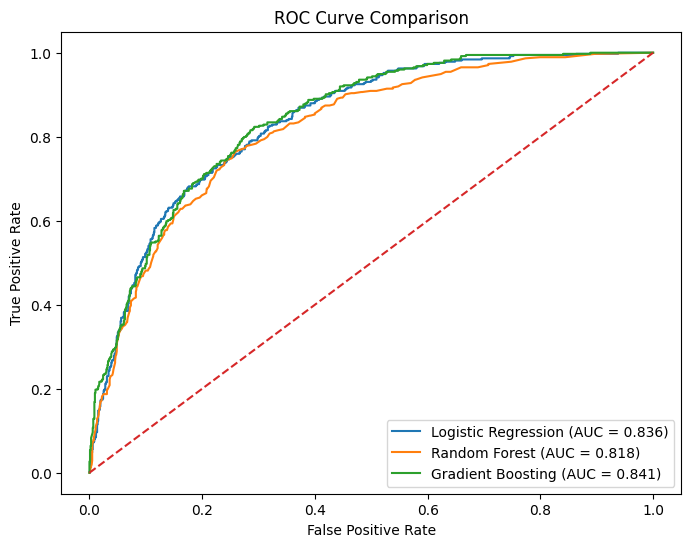

In [53]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_prob)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_prob)
gb_fpr, gb_tpr, _ = roc_curve(y_test, gb_prob)

plt.figure(figsize=(8, 6))

plt.plot(lr_fpr, lr_tpr, label=f"Logistic Regression (AUC = {lr_auc:.3f})")
plt.plot(rf_fpr, rf_tpr, label=f"Random Forest (AUC = {rf_auc:.3f})")
plt.plot(gb_fpr, gb_tpr, label=f"Gradient Boosting (AUC = {gb_auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()

plt.show()

ROC-AUC Comparison

Gradient Boosting achieved the highest ROC-AUC of 0.841, slightly outperforming Logistic Regression (0.836) and Random Forest (0.818). All three models performed substantially better than random classification.

In [54]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, gb_pred)
    ],
    "ROC_AUC": [
        lr_auc,
        rf_auc,
        gb_auc
    ]
})

comparison

,Model,Accuracy,ROC_AUC
0,Logistic Regression,0.801706,0.836405
1,Random Forest,0.787491,0.818373
2,Gradient Boosting,0.796020,0.840601


In [55]:
from sklearn.metrics import precision_score, recall_score, f1_score

comparison["Precision_Churn"] = [
    precision_score(y_test, y_pred),
    precision_score(y_test, rf_pred),
    precision_score(y_test, gb_pred)
]

comparison["Recall_Churn"] = [
    recall_score(y_test, y_pred),
    recall_score(y_test, rf_pred),
    recall_score(y_test, gb_pred)
]

comparison["F1_Churn"] = [
    f1_score(y_test, y_pred),
    f1_score(y_test, rf_pred),
    f1_score(y_test, gb_pred)
]

comparison.round(3)

,Model,Accuracy,ROC_AUC,Precision_Churn,Recall_Churn,F1_Churn
0,Logistic Regression,0.802,0.836,0.643,0.572,0.605
1,Random Forest,0.787,0.818,0.623,0.508,0.560
2,Gradient Boosting,0.796,0.841,0.641,0.529,0.580


In [56]:
threshold = 0.45

lr_pred_045 = (lr_prob >= threshold).astype(int)

In [57]:
print(classification_report(y_test, lr_pred_045))

              precision    recall  f1-score   support

           0       0.87      0.85      0.86      1033
           1       0.61      0.63      0.62       374

    accuracy                           0.79      1407
   macro avg       0.74      0.74      0.74      1407
weighted avg       0.80      0.79      0.80      1407



In [58]:
confusion_matrix(y_test, lr_pred_045)

array([[880, 153],
       [137, 237]])

In [59]:
thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

results = []

for t in thresholds:
    pred = (lr_prob >= t).astype(int)

    results.append({
        "Threshold": t,
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "Accuracy": accuracy_score(y_test, pred)
    })

threshold_results = pd.DataFrame(results)

threshold_results.round(3)

,Threshold,Precision,Recall,F1,Accuracy
0,0.30,0.514,0.759,0.613,0.745
1,0.35,0.544,0.722,0.621,0.765
2,0.40,0.577,0.682,0.625,0.783
3,0.45,0.608,0.634,0.620,0.794
4,0.50,0.643,0.572,0.605,0.802
5,0.55,0.673,0.489,0.567,0.801
6,0.60,0.686,0.385,0.493,0.790


Threshold Tuning

Reducing the classification threshold from 0.50 to 0.40 increased churn recall from 0.572 to 0.682 and improved the churn F1-score from 0.605 to 0.625. Although precision and overall accuracy decreased slightly, a threshold of 0.40 provides a better balance for identifying customers at risk of churn.

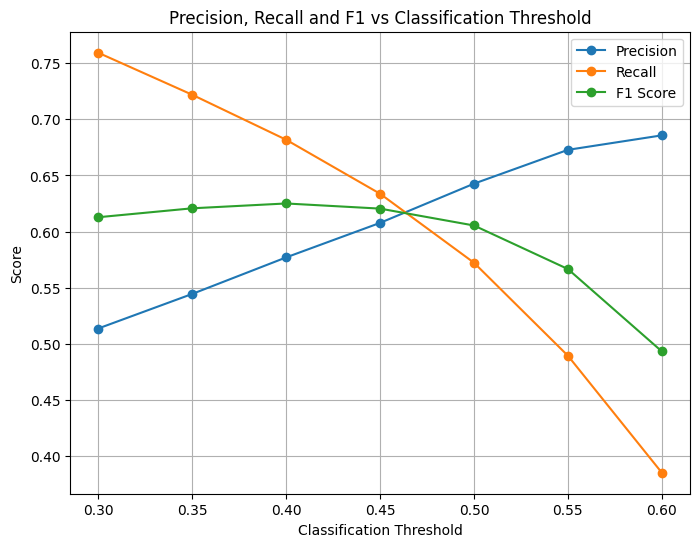

In [60]:
plt.figure(figsize=(8, 6))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["F1"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1 vs Classification Threshold")
plt.legend()
plt.grid(True)

plt.show()

Threshold Selection

As the classification threshold increases, precision improves while recall decreases. The F1-score reaches its highest value at a threshold of 0.40, indicating the best balance between precision and recall for churn detection in this model.

In [61]:
import pandas as pd

lr_importance = pd.DataFrame({
    "Feature": X_encoded.columns,
    "Coefficient": model.coef_[0]
})

lr_importance.head()

,Feature,Coefficient
0,SeniorCitizen,0.190808
1,tenure,-0.057253
2,MonthlyCharges,0.002016
3,TotalCharges,0.000306
4,gender_Male,-0.025344


In [62]:
lr_importance.sort_values(
    by="Coefficient",
    ascending=False
).head(10)

,Feature,Coefficient
10,InternetService_Fiber optic,0.692779
28,PaymentMethod_Electronic check,0.384283
26,PaperlessBilling_Yes,0.293391
9,MultipleLines_Yes,0.281212
8,MultipleLines_No phone service,0.258415
21,StreamingTV_Yes,0.204352
0,SeniorCitizen,0.190808
23,StreamingMovies_Yes,0.175604
29,PaymentMethod_Mailed check,0.083166
27,PaymentMethod_Credit card (automatic),0.042904


In [63]:
lr_importance["AbsCoefficient"] = lr_importance["Coefficient"].abs()

top_lr_features = lr_importance.sort_values(
    by="AbsCoefficient",
    ascending=False
).head(10)

top_lr_features

,Feature,Coefficient,AbsCoefficient
25,Contract_Two year,-1.369678,1.369678
24,Contract_One year,-0.754809,0.754809
10,InternetService_Fiber optic,0.692779,0.692779
13,OnlineSecurity_Yes,-0.455146,0.455146
7,PhoneService_Yes,-0.433885,0.433885
19,TechSupport_Yes,-0.416956,0.416956
28,PaymentMethod_Electronic check,0.384283,0.384283
26,PaperlessBilling_Yes,0.293391,0.293391
9,MultipleLines_Yes,0.281212,0.281212
8,MultipleLines_No phone service,0.258415,0.258415


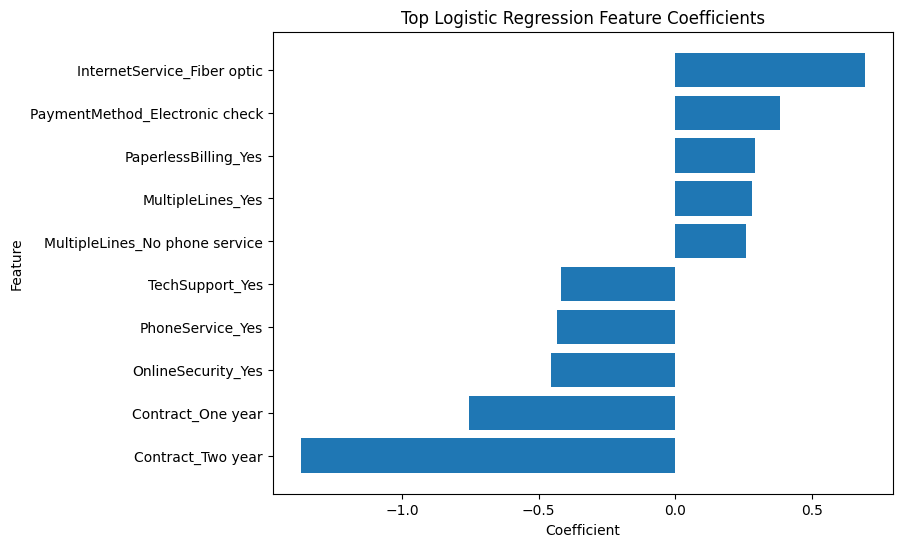

In [64]:
top_lr_features = top_lr_features.sort_values("Coefficient")

plt.figure(figsize=(8, 6))
plt.barh(
    top_lr_features["Feature"],
    top_lr_features["Coefficient"]
)

plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.title("Top Logistic Regression Feature Coefficients")
plt.show()

Logistic Regression Interpretation

The Logistic Regression model indicates that fiber optic internet, electronic check payment, and paperless billing are associated with a higher likelihood of churn. In contrast, longer-term contracts, online security, phone service, and technical support are associated with a lower likelihood of churn. The large negative coefficients for one-year and two-year contracts are consistent with the earlier EDA, where customers on longer contracts showed substantially lower churn rates. These coefficients represent associations within the model and should not be interpreted as causal effects.

In [65]:
gb_importance = pd.DataFrame({
    "Feature": X_encoded.columns,
    "Importance": gb_model.feature_importances_
})

In [66]:
gb_importance = gb_importance.sort_values(
    by="Importance",
    ascending=False
)

gb_importance.head(10)

,Feature,Importance
1,tenure,0.319089
10,InternetService_Fiber optic,0.191894
28,PaymentMethod_Electronic check,0.097709
25,Contract_Two year,0.072151
3,TotalCharges,0.065283
24,Contract_One year,0.060404
2,MonthlyCharges,0.059251
13,OnlineSecurity_Yes,0.022459
26,PaperlessBilling_Yes,0.015000
19,TechSupport_Yes,0.011210


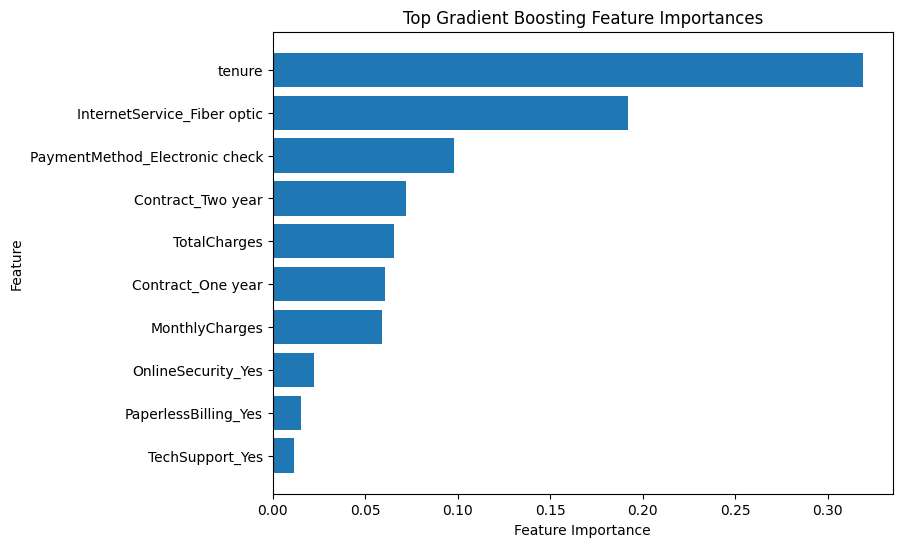

In [67]:
top_gb_features = gb_importance.head(10).sort_values("Importance")

plt.figure(figsize=(8, 6))
plt.barh(
    top_gb_features["Feature"],
    top_gb_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top Gradient Boosting Feature Importances")
plt.show()

Gradient Boosting Feature Importance

The Gradient Boosting model identifies tenure as the most important feature for predicting customer churn, followed by fiber optic internet service and electronic check payment. Contract type, total charges, and monthly charges also contribute substantially to the model's predictions. These results are broadly consistent with the EDA, particularly the strong relationship observed between shorter tenure, fiber optic service, and higher churn rates. Unlike Logistic Regression coefficients, Gradient Boosting feature importance measures how useful a feature is for prediction, but does not indicate whether the feature increases or decreases churn risk.

In [70]:
import shap

explainer = shap.TreeExplainer(gb_model)
shap_values = explainer.shap_values(X_test)

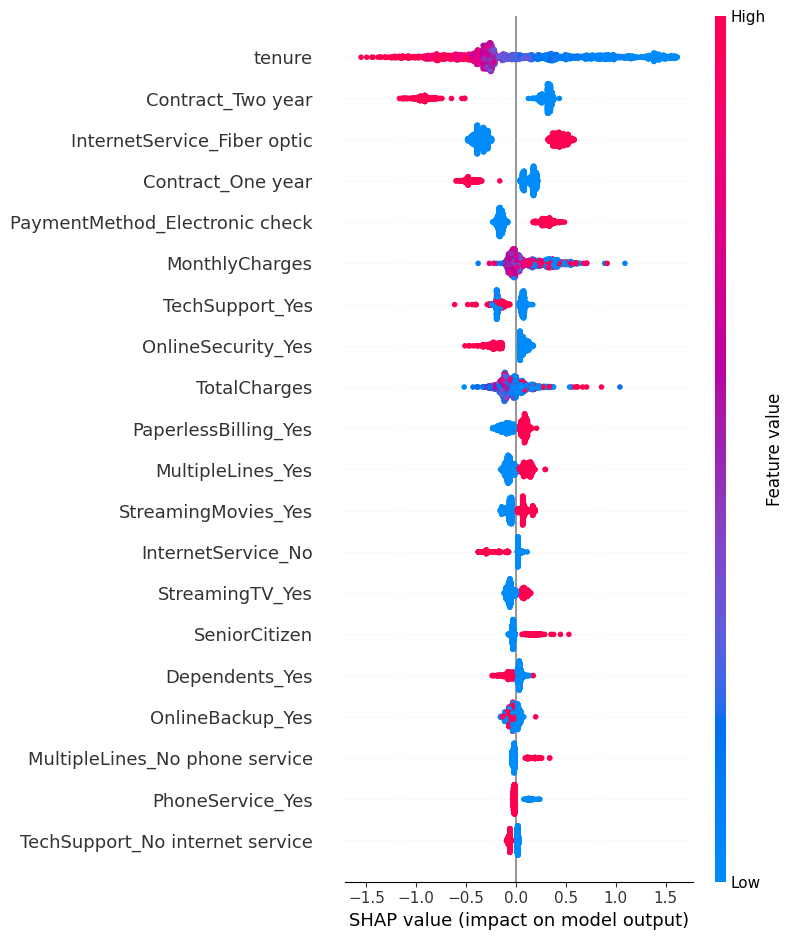

In [71]:
shap.summary_plot(
    shap_values,
    X_test,
    feature_names=X_test.columns
)

SHAP Model Interpretation

SHAP analysis provides both the importance and direction of each feature's contribution to churn predictions. Shorter tenure, fiber optic internet service, and electronic check payment tend to increase predicted churn risk. In contrast, longer tenure, one-year or two-year contracts, technical support, and online security tend to reduce predicted churn risk. These findings are broadly consistent with the earlier exploratory analysis and provide additional insight into how the Gradient Boosting model makes its predictions.